# 02 · Classical Baseline: TF-IDF with Logistic Regression or Linear SVM
*Model family 1 of 3: a fast, transparent baseline that the later models are compared against.*

1. **Aspect sentiment classification**: given a sentence and an aspect category, predict positive, negative
   or neutral. Features are word 1–2-grams, character 2–5-grams (which handle Arabic prefixes and suffixes)
   and the aspect category as a one-hot vector.
2. **Preprocessing ablation**: raw, light, full, full + stopword removal, full + stopwords + stemming.
3. **Class-weighting ablation**: no weights vs `class_weight="balanced"`.
4. **Evaluation**: per-class precision, recall and F1, macro-F1, confusion matrix, per-entity and slice results.
5. **Interpretability**: the n-grams that push the model towards each class.
6. **Aspect category detection**: which of the 7 entities a sentence talks about (multi-label), used by the
   demo in notebook 04 for new reviews that have no labels.

Runs on CPU in about 10–15 minutes. Requires the output of notebook 01.

In [1]:
# Paths, libraries and the train/validation/test files created in notebook 01.
import os, sys, json, time, random, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/MAAI902_ABSA"
else:
    BASE = "./MAAI902_ABSA"
DATA_DIR, FIG_DIR, RES_DIR, MODEL_DIR = (os.path.join(BASE, d) for d in ("data", "figures", "results", "models"))
for d in (FIG_DIR, RES_DIR, MODEL_DIR):
    os.makedirs(d, exist_ok=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, MultiLabelBinarizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, accuracy_score, precision_recall_fscore_support)

SEED = 42; random.seed(SEED); np.random.seed(SEED)
LABELS = ["positive", "negative", "neutral"]
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

train = pd.read_csv(f"{DATA_DIR}/train.csv")
val = pd.read_csv(f"{DATA_DIR}/val.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print(len(train), len(val), len(test))

Mounted at /content/drive
7787 1392 2604


## 1. Feature pipeline
The aspect category is given to the model as a separate one-hot feature, so the same sentence can receive
different labels for different aspects (e.g. *room* negative, *staff* positive).

In [2]:
def make_pipeline(text_col, clf="lr", C=1.0, balanced=False):
    """TF-IDF word + character n-grams plus a one-hot aspect category, followed by LR or a linear SVM."""
    text_feats = FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True, max_features=60000)),
    ])
    feats = ColumnTransformer([
        ("text", text_feats, text_col),
        ("aspect", OneHotEncoder(handle_unknown="ignore"), ["category"]),
    ])
    cw = "balanced" if balanced else None
    model = (LogisticRegression(C=C, max_iter=3000, class_weight=cw, random_state=SEED) if clf == "lr"
             else LinearSVC(C=C, class_weight=cw, random_state=SEED))
    return Pipeline([("features", feats), ("clf", model)])

def scores(y_true, y_pred):
    """Accuracy, macro-F1 and per-class precision, recall and F1."""
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    out = {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0)}
    for i, l in enumerate(LABELS):
        out[f"{l}_P"], out[f"{l}_R"], out[f"{l}_F1"] = p[i], r[i], f[i]
    return out

## 2. Ablation: preprocessing level × classifier × class weighting
Every combination is trained on the training set and scored on the validation set only (40 small models).

In [3]:
# Each preprocessing level corresponds to one text column created in notebook 01.
TEXT_VARIANTS = {"raw": "sentence", "light": "text_light", "full": "text_full",
                 "full+stopwords": "text_full_sw", "full+stopwords+stem": "text_full_sw_stem"}
rows = []
for prep, col in TEXT_VARIANTS.items():
    for clf in ["lr", "svm"]:
        for balanced in [False, True]:
            for C in [0.5, 2.0]:
                t0 = time.time()
                pipe = make_pipeline(col, clf, C, balanced).fit(train, train["sentiment"])
                s = scores(val["sentiment"], pipe.predict(val))
                rows.append({"preprocessing": prep, "classifier": clf, "class_weight": "balanced" if balanced else "none",
                             "C": C, **s, "fit_seconds": round(time.time() - t0, 1)})
abl = pd.DataFrame(rows).sort_values("macro_f1", ascending=False)
abl.to_csv(f"{RES_DIR}/02_baseline_ablation_val.csv", index=False)
abl.head(10)[["preprocessing", "classifier", "class_weight", "C", "accuracy", "macro_f1", "neutral_F1"]]

,preprocessing,classifier,class_weight,C,accuracy,macro_f1,neutral_F1
35,full+stopwords+stem,lr,balanced,2.0,0.798851,0.697183,0.424710
18,full,lr,balanced,0.5,0.790948,0.695573,0.431227
34,full+stopwords+stem,lr,balanced,0.5,0.784483,0.690224,0.417219
26,full+stopwords,lr,balanced,0.5,0.788075,0.690016,0.411348
27,full+stopwords,lr,balanced,2.0,0.800287,0.685610,0.381356
19,full,lr,balanced,2.0,0.801006,0.683806,0.377193
11,light,lr,balanced,2.0,0.797414,0.681431,0.380531
10,light,lr,balanced,0.5,0.780891,0.680480,0.402985
2,raw,lr,balanced,0.5,0.779454,0.679504,0.402985
30,full+stopwords,svm,balanced,0.5,0.814655,0.678807,0.350282


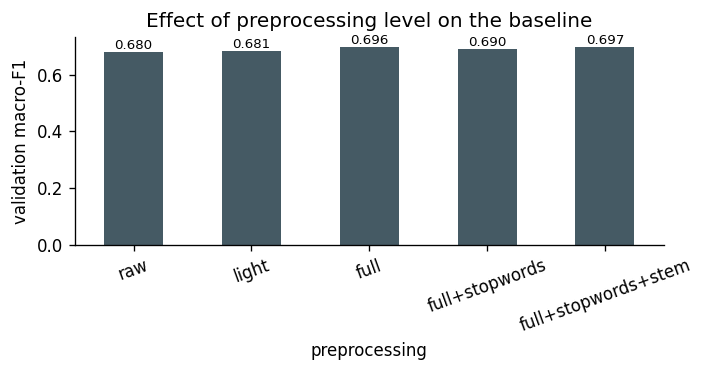

,classifier,class_weight,C,accuracy,macro_f1,neutral_F1
preprocessing,,,,,,
raw,lr,balanced,0.5,0.779454,0.679504,0.402985
light,lr,balanced,2.0,0.797414,0.681431,0.380531
full,lr,balanced,0.5,0.790948,0.695573,0.431227
full+stopwords,lr,balanced,0.5,0.788075,0.690016,0.411348
full+stopwords+stem,lr,balanced,2.0,0.798851,0.697183,0.424710


In [4]:
# Best validation macro-F1 reached with each preprocessing level.
best_per_prep = abl.loc[abl.groupby("preprocessing")["macro_f1"].idxmax(), ["preprocessing", "classifier", "class_weight", "C", "accuracy", "macro_f1", "neutral_F1"]]
best_per_prep = best_per_prep.set_index("preprocessing").loc[list(TEXT_VARIANTS)]
fig, ax = plt.subplots(figsize=(6, 3.2))
best_per_prep["macro_f1"].plot.bar(ax=ax, color="#455A64", rot=20)
ax.set_ylabel("validation macro-F1"); ax.set_title("Effect of preprocessing level on the baseline")
ax.bar_label(ax.containers[0], fmt="%.3f", fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig3_preprocessing_ablation.png", bbox_inches="tight"); plt.show()
best_per_prep

## 3. Final baseline
The best validation configuration is refitted on the training set and evaluated once on the test set.

In [5]:
# Refit the best configuration and print the per-class test results.
best = abl.iloc[0]
print("Best validation config:", best[["preprocessing", "classifier", "class_weight", "C"]].to_dict())
final = make_pipeline(TEXT_VARIANTS[best["preprocessing"]], best["classifier"], best["C"], best["class_weight"] == "balanced")
final.fit(train, train["sentiment"])
test_pred = final.predict(test)

print(classification_report(test["sentiment"], test_pred, labels=LABELS, digits=3, zero_division=0))
base_scores = scores(test["sentiment"], test_pred)

# A plain logistic regression without class weights, to show what class weighting changes.
plain = make_pipeline(TEXT_VARIANTS[best["preprocessing"]], "lr", 1.0, False).fit(train, train["sentiment"])
plain_scores = scores(test["sentiment"], plain.predict(test))
pd.DataFrame({"no class weights": plain_scores, "best (validation-selected)": base_scores}).T[
    ["accuracy", "macro_f1", "neutral_P", "neutral_R", "neutral_F1"]].round(3)

Best validation config: {'preprocessing': 'full+stopwords+stem', 'classifier': 'lr', 'class_weight': 'balanced', 'C': 2.0}
              precision    recall  f1-score   support

    positive      0.892     0.850     0.870      1508
    negative      0.847     0.857     0.852       927
     neutral      0.253     0.343     0.291       169

    accuracy                          0.820      2604
   macro avg      0.664     0.683     0.671      2604
weighted avg      0.834     0.820     0.826      2604



,accuracy,macro_f1,neutral_P,neutral_R,neutral_F1
no class weights,0.844,0.638,0.442,0.112,0.179
best (validation-selected),0.820,0.671,0.253,0.343,0.291


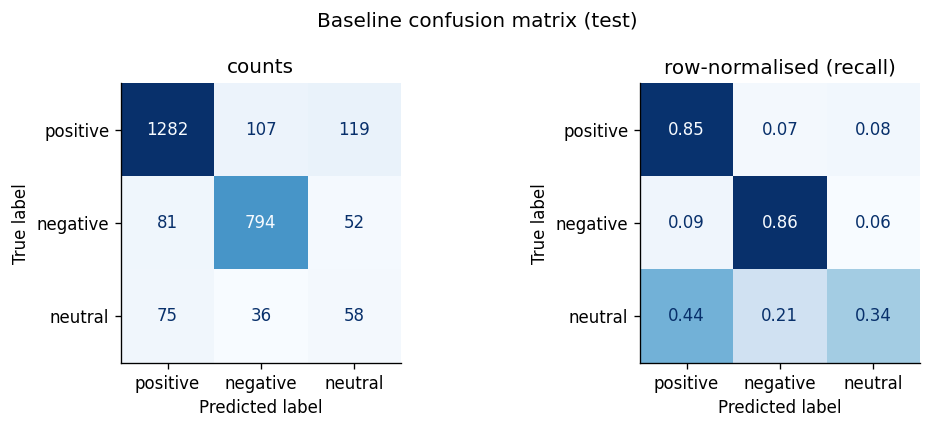

In [6]:
# Confusion matrix on the test set, as counts and normalised by the true class (recall).
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, norm, title in [(axes[0], None, "counts"), (axes[1], "true", "row-normalised (recall)")]:
    ConfusionMatrixDisplay.from_predictions(test["sentiment"], test_pred, labels=LABELS, normalize=norm,
                                            cmap="Blues", ax=ax, colorbar=False, values_format=".2f" if norm else "d")
    ax.set_title(title)
fig.suptitle("Baseline confusion matrix (test)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig4_baseline_confusion.png", bbox_inches="tight"); plt.show()

In [7]:
# Where does the baseline struggle? Macro-F1 per entity, and on sentences with contrast words or implicit aspects.
test_out = test[["row_id", "sentence", "category", "entity", "sentiment", "has_contrast", "implicit"]].copy()
test_out["pred_baseline"] = test_pred
per_entity = (test_out.groupby("entity")
              .apply(lambda g: pd.Series({"n": len(g), "macro_f1": f1_score(g["sentiment"], g["pred_baseline"], average="macro", labels=LABELS, zero_division=0),
                                          "accuracy": accuracy_score(g["sentiment"], g["pred_baseline"])}))
              .sort_values("macro_f1"))
slices = pd.DataFrame({
    "with contrast marker": scores(test_out.loc[test_out.has_contrast, "sentiment"], test_out.loc[test_out.has_contrast, "pred_baseline"]),
    "without contrast marker": scores(test_out.loc[~test_out.has_contrast, "sentiment"], test_out.loc[~test_out.has_contrast, "pred_baseline"]),
    "implicit aspect": scores(test_out.loc[test_out.implicit, "sentiment"], test_out.loc[test_out.implicit, "pred_baseline"]),
    "explicit aspect": scores(test_out.loc[~test_out.implicit, "sentiment"], test_out.loc[~test_out.implicit, "pred_baseline"]),
}).T[["accuracy", "macro_f1", "neutral_F1"]]
display_tables = (per_entity, slices)
per_entity

,n,macro_f1,accuracy
entity,,,
LOCATION,303.0,0.480342,0.818482
ROOMS_AMENITIES,160.0,0.588235,0.800000
SERVICE,560.0,0.613510,0.867857
FACILITIES,340.0,0.656424,0.814706
ROOMS,312.0,0.657255,0.791667
HOTEL,693.0,0.691402,0.822511
FOOD_DRINKS,236.0,0.705420,0.754237


In [8]:
# Results on sentences with contrast words and on implicit vs explicit aspects.
slices

,accuracy,macro_f1,neutral_F1
with contrast marker,0.673770,0.593189,0.309278
without contrast marker,0.864092,0.688098,0.274510
implicit aspect,0.801724,0.646698,0.315789
explicit aspect,0.821248,0.672703,0.290237


## 4. Interpretability: which n-grams drive each class?
Logistic regression weights show the words most strongly associated with each sentiment.

In [9]:
# Top 15 word n-grams for each class, from a class-weighted logistic regression. The unstemmed "full" text is
# used here so the words stay readable; its validation score is within a fraction of a point of the best setting.
interp = make_pipeline(TEXT_VARIANTS["full"], "lr", 1.0, True).fit(train, train["sentiment"])
names = interp.named_steps["features"].get_feature_names_out()
coefs = interp.named_steps["clf"].coef_
top = {}
for i, cls in enumerate(interp.named_steps["clf"].classes_):
    idx = np.argsort(coefs[i])[::-1]
    words = [names[j].split("__")[-1] for j in idx if names[j].startswith("text__word")][:15]
    top[cls] = words
top_df = pd.DataFrame(top)
top_df.to_csv(f"{RES_DIR}/02_top_ngrams.csv", index=False)
top_df

,negative,neutral,positive
0,لا,جيد,رايع
1,غير,عادي,كل
2,سييه,مقبول,رايعه
3,سيء,باس,جيد جدا
4,لم,لا باس,ممتازه
5,اسوا,فندق جيد,جميل
6,سيي,جيده,اجمل
7,رايحه,كانت جيده,الطعام جيد
8,لا انصح,باس به,جميله
9,عدم,مقبوله,جيده جدا


## 5. Aspect category detection (multi-label, 7 entities)
This lets the demo handle new reviews that have no aspect labels: it predicts which entities each sentence
mentions, and the sentiment model then scores each one.

In [10]:
def sent_level(df):
    """One row per sentence with the list of entities it mentions."""
    g = df.groupby("sentence").agg(text_full=("text_full", "first"), entities=("entity", lambda s: sorted(set(s)))).reset_index()
    return g

acd_tr, acd_va, acd_te = sent_level(train), sent_level(val), sent_level(test)
mlb = MultiLabelBinarizer().fit(pd.concat([acd_tr, acd_va, acd_te])["entities"])
Ytr, Yva, Yte = (mlb.transform(d["entities"]) for d in (acd_tr, acd_va, acd_te))

acd_vec = FeatureUnion([("w", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                        ("c", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True))])
acd = Pipeline([("vec", acd_vec), ("clf", OneVsRestClassifier(LogisticRegression(C=4.0, max_iter=3000, class_weight="balanced")))])
acd.fit(acd_tr["text_full"], Ytr)

# One probability threshold for all entities, chosen on the validation set.
probs_va = acd.predict_proba(acd_va["text_full"])
ths = np.arange(0.2, 0.81, 0.05)
best_th = max(ths, key=lambda t: f1_score(Yva, (probs_va >= t).astype(int), average="micro", zero_division=0))
Yhat = (acd.predict_proba(acd_te["text_full"]) >= best_th).astype(int)
acd_scores = {"threshold": float(best_th),
              "micro_f1": f1_score(Yte, Yhat, average="micro", zero_division=0),
              "macro_f1": f1_score(Yte, Yhat, average="macro", zero_division=0)}
print("ACD test:", acd_scores)
acd_per_class = pd.DataFrame({"entity": mlb.classes_, "F1": f1_score(Yte, Yhat, average=None, zero_division=0), "support": Yte.sum(0)})
acd_per_class

ACD test: {'threshold': 0.49999999999999994, 'micro_f1': 0.7552070570938495, 'macro_f1': 0.742938847820585}


,entity,F1,support
0,FACILITIES,0.659048,264
1,FOOD_DRINKS,0.833333,200
2,HOTEL,0.699620,538
3,LOCATION,0.777563,258
4,ROOMS,0.777778,247
5,ROOMS_AMENITIES,0.588745,118
6,SERVICE,0.864486,438


## 6. Save the models, predictions and results
The test predictions are shared with notebooks 03 and 04, which add their own columns to the same file.

In [11]:
joblib.dump(final, f"{MODEL_DIR}/baseline_asc.joblib")
joblib.dump({"model": acd, "mlb": mlb, "threshold": float(best_th)}, f"{MODEL_DIR}/baseline_acd.joblib")
pred_path = f"{RES_DIR}/predictions_test.csv"
if os.path.exists(pred_path):                  # keep columns already added by notebook 03 if this is re-run
    old = pd.read_csv(pred_path)
    keep = [c for c in old.columns if c not in test_out.columns and c != "row_id"]
    if keep and len(old) == len(test_out):
        test_out = test_out.merge(old[["row_id"] + keep], on="row_id", how="left")
test_out.to_csv(pred_path, index=False)

results = {"best_config": {k: (v if isinstance(v, str) else float(v)) for k, v in best[["preprocessing", "classifier", "class_weight", "C"]].items()},
           "test_best_baseline": base_scores, "test_plain_lr_no_weights": plain_scores,
           "slices": slices.to_dict(), "per_entity": per_entity.to_dict(), "acd": acd_scores}
with open(f"{RES_DIR}/02_baseline_results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2, default=float)
print(json.dumps({"test_best_baseline": base_scores, "acd": acd_scores}, indent=2, default=float))

{
  "test_best_baseline": {
    "accuracy": 0.8195084485407066,
    "macro_f1": 0.6712404237836571,
    "positive_P": 0.8915159944367177,
    "positive_R": 0.850132625994695,
    "positive_F1": 0.8703326544467074,
    "negative_P": 0.847385272145144,
    "negative_R": 0.8565264293419633,
    "negative_F1": 0.851931330472103,
    "neutral_P": 0.25327510917030566,
    "neutral_R": 0.3431952662721893,
    "neutral_F1": 0.2914572864321608
  },
  "acd": {
    "threshold": 0.49999999999999994,
    "micro_f1": 0.7552070570938495,
    "macro_f1": 0.742938847820585
  }
}
